In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
CLASSES = ["Good", "Moderate", "Poor"]
FEATURES = ["gas_ppm", "temperature_c", "humidity_pct"]

In [4]:
df = pd.read_csv("classroom_air_quality.csv")
print("Shape:", df.shape)
df.head()

Shape: (3000, 5)


,gas_ppm,temperature_c,humidity_pct,scenario,air_quality
0,1834.1,30.0,59.3,closed_long,Poor
1,2591.2,27.0,63.6,closed_long,Poor
2,1450.5,29.5,72.5,crowded_class,Moderate
3,1138.6,22.5,66.2,crowded_class,Moderate
4,773.9,27.5,48.3,normal_class,Good


In [5]:
print("Missing values per column:")
print(df.isna().sum(), "\n")
df.describe().round(1)

Missing values per column:
gas_ppm          0
temperature_c    0
humidity_pct     0
scenario         0
air_quality      0
dtype: int64 



,gas_ppm,temperature_c,humidity_pct
count,3000.0,3000.0,3000.0
mean,1169.6,27.4,60.4
std,650.9,3.0,11.2
min,350.0,18.5,29.9
25%,625.4,25.0,52.2
50%,960.2,27.2,59.0
75%,1617.9,29.6,67.5
max,3000.0,36.7,95.0


In [6]:
print("Class balance:")
print(df["air_quality"].value_counts(), "\n")
print("Which scenarios produce which labels?")
pd.crosstab(df["scenario"], df["air_quality"])

Class balance:
air_quality
Moderate    1141
Poor         965
Good         894
Name: count, dtype: int64 

Which scenarios produce which labels?


air_quality,Good,Moderate,Poor
scenario,,,
closed_long,11,56,433
crowded_class,16,423,161
empty_ventilated,581,9,10
hot_humid_day,11,225,64
normal_class,268,420,12
smoke_or_fumes,7,8,285


Visualise
We want to see whether the classes separate in the data. If gas level clearly differs between Good and Poor, a tree will find it easily.

C:\Users\LENOVO\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\LENOVO\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\LENOVO\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


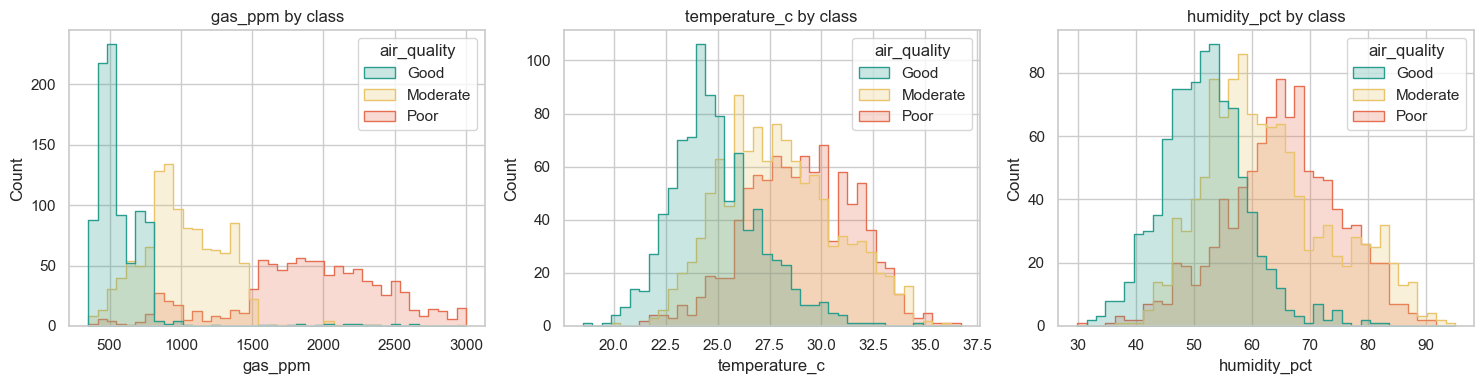

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette = {"Good": "#2a9d8f", "Moderate": "#e9c46a", "Poor": "#e76f51"}
for ax, col in zip(axes, FEATURES):
    sns.histplot(data=df, x=col, hue="air_quality", hue_order=CLASSES,
                 palette=palette, bins=40, element="step", ax=ax)
    ax.set_title(f"{col} by class")
plt.tight_layout(); plt.show()

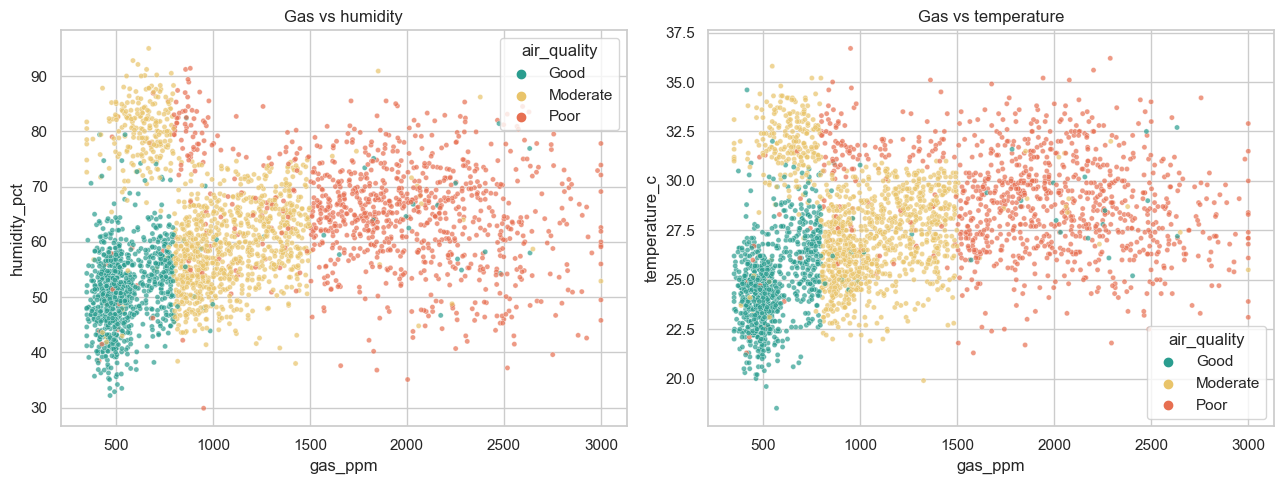

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="gas_ppm", y="humidity_pct", hue="air_quality",
                hue_order=CLASSES, palette=palette, s=14, alpha=.7, ax=axes[0])
axes[0].set_title("Gas vs humidity")
sns.scatterplot(data=df, x="gas_ppm", y="temperature_c", hue="air_quality",
                hue_order=CLASSES, palette=palette, s=14, alpha=.7, ax=axes[1])
axes[1].set_title("Gas vs temperature")
plt.tight_layout(); plt.show()

In [9]:
def rule_label(r):
    s = 0 if r.gas_ppm < 800 else (1 if r.gas_ppm < 1500 else 2)
    if r.temperature_c > 31 or r.humidity_pct > 75 or r.humidity_pct < 30:
        s += 1
    return CLASSES[min(s, 2)]

agree = (df.apply(rule_label, axis=1) == df["air_quality"]).mean()
print(f"Rule agrees with the labels on {agree:.1%} of rows")

Rule agrees with the labels on 96.9% of rows


Split into train and test sets
The tree learns from 80 % of the data. The other 20 % is kept hidden until the end, so the score reflects how it handles readings it has never seen.
`stratify=y` keeps the same class proportions in both sets.

In [10]:
X = df[FEATURES]
y = df["air_quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (2400, 3)  Test: (600, 3)


Train the decision tree
`max_depth=4` keeps the tree small enough to read and to fit on a microcontroller. Step 8 shows why this is a sensible choice.

In [11]:
model = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
model.fit(X_train, y_train)
print("Trained. Depth:", model.get_depth(), " Leaves:", model.get_n_leaves())

Trained. Depth: 4  Leaves: 13


Evaluate

In [12]:
pred = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f}\n")
print(classification_report(y_test, pred, target_names=CLASSES))

Test accuracy: 0.948

              precision    recall  f1-score   support

        Good       0.93      0.95      0.94       179
    Moderate       0.95      0.95      0.95       228
        Poor       0.96      0.95      0.96       193

    accuracy                           0.95       600
   macro avg       0.95      0.95      0.95       600
weighted avg       0.95      0.95      0.95       600



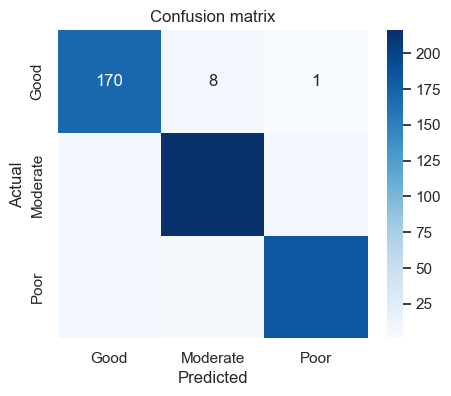

In [13]:
cm = confusion_matrix(y_test, pred, labels=CLASSES)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.show()

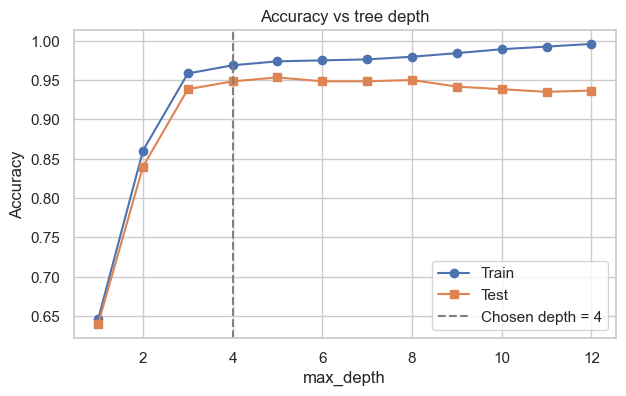

In [14]:
depths = range(1, 13)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, "o-", label="Train")
plt.plot(depths, test_acc, "s-", label="Test")
plt.axvline(4, ls="--", color="grey", label="Chosen depth = 4")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Accuracy vs tree depth"); plt.show()

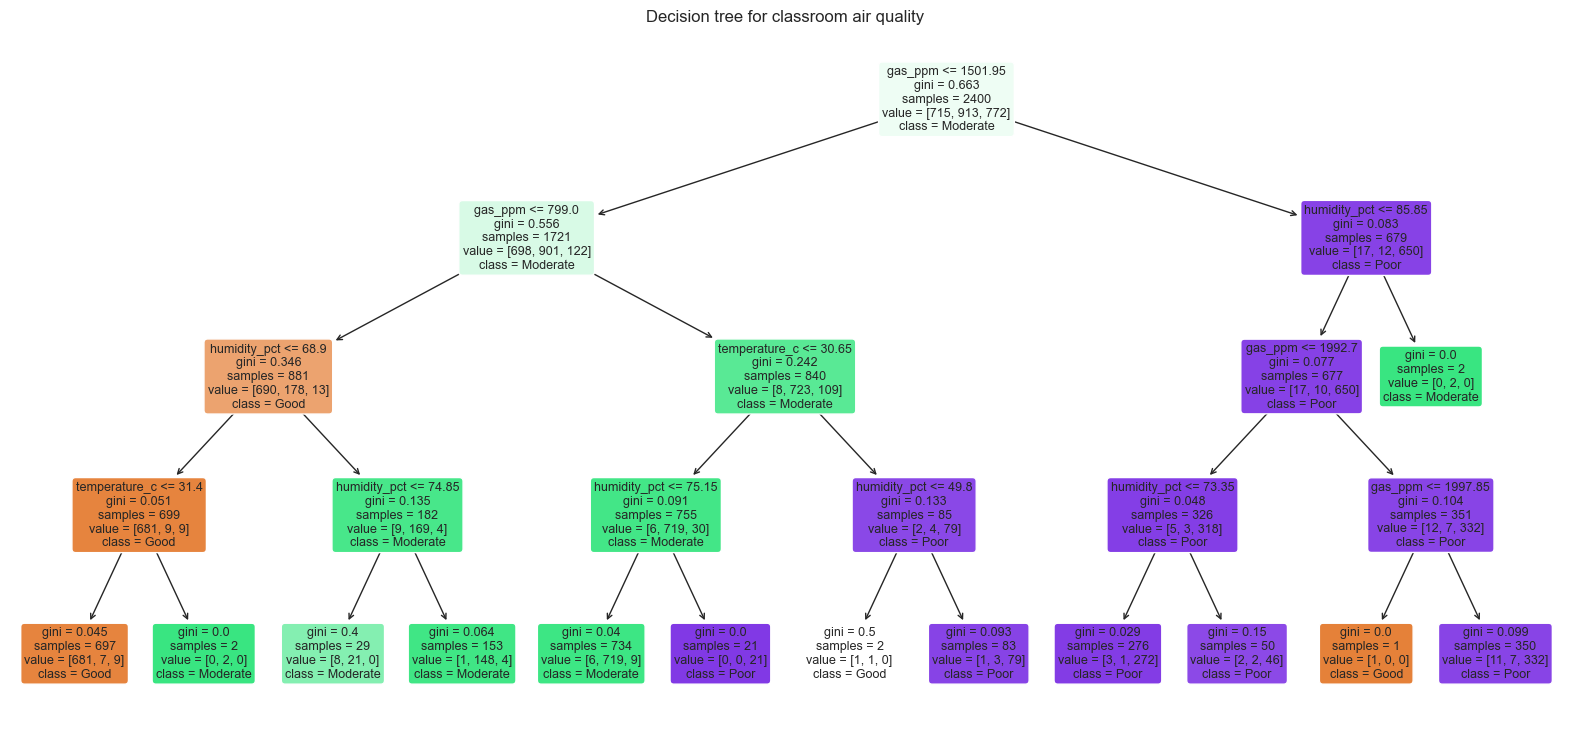

In [15]:
plt.figure(figsize=(20, 9))
plot_tree(model, feature_names=FEATURES, class_names=model.classes_,
          filled=True, rounded=True, fontsize=9)
plt.title("Decision tree for classroom air quality")
plt.show()

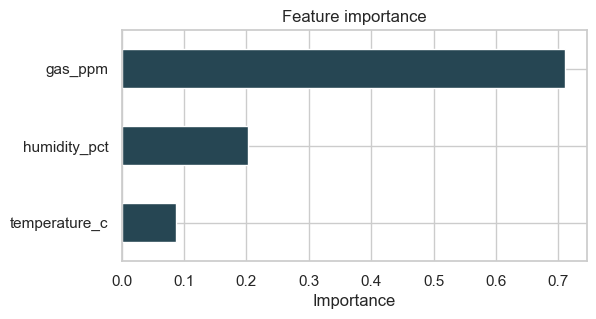

gas_ppm          0.710
humidity_pct     0.203
temperature_c    0.088
dtype: float64


In [16]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", color="#264653", figsize=(6, 3))
plt.title("Feature importance"); plt.xlabel("Importance"); plt.show()
print(imp.sort_values(ascending=False).round(3))

In [17]:
print(export_text(model, feature_names=FEATURES))

|--- gas_ppm <= 1501.95
|   |--- gas_ppm <= 799.00
|   |   |--- humidity_pct <= 68.90
|   |   |   |--- temperature_c <= 31.40
|   |   |   |   |--- class: Good
|   |   |   |--- temperature_c >  31.40
|   |   |   |   |--- class: Moderate
|   |   |--- humidity_pct >  68.90
|   |   |   |--- humidity_pct <= 74.85
|   |   |   |   |--- class: Moderate
|   |   |   |--- humidity_pct >  74.85
|   |   |   |   |--- class: Moderate
|   |--- gas_ppm >  799.00
|   |   |--- temperature_c <= 30.65
|   |   |   |--- humidity_pct <= 75.15
|   |   |   |   |--- class: Moderate
|   |   |   |--- humidity_pct >  75.15
|   |   |   |   |--- class: Poor
|   |   |--- temperature_c >  30.65
|   |   |   |--- humidity_pct <= 49.80
|   |   |   |   |--- class: Good
|   |   |   |--- humidity_pct >  49.80
|   |   |   |   |--- class: Poor
|--- gas_ppm >  1501.95
|   |--- humidity_pct <= 85.85
|   |   |--- gas_ppm <= 1992.70
|   |   |   |--- humidity_pct <= 73.35
|   |   |   |   |--- class: Poor
|   |   |   |--- humidity_p

Generate C code for the ESP32
The ESP32 never needs scikit-learn. We walk through the trained tree and write out an equivalent C function that takes the three readings and returns 0, 1 or 2 (Good, Moderate, Poor).

In [18]:
def tree_to_c(model, feature_names, func_name="predictAirQuality"):
    t = model.tree_
    class_idx = {c: i for i, c in enumerate(model.classes_)}
    lines = [f"int {func_name}(float gas, float temp, float hum) {{"]
    names = {"gas_ppm": "gas", "temperature_c": "temp", "humidity_pct": "hum"}

    def walk(node, indent):
        pad = "  " * indent
        if t.feature[node] == -2:                      # leaf
            cls = model.classes_[np.argmax(t.value[node])]
            lines.append(f"{pad}return {class_idx[cls]};  // {cls}")
            return
        var = names[feature_names[t.feature[node]]]
        lines.append(f"{pad}if ({var} <= {t.threshold[node]:.2f}f) {{")
        walk(t.children_left[node], indent + 1)
        lines.append(f"{pad}}} else {{")
        walk(t.children_right[node], indent + 1)
        lines.append(f"{pad}}}")

    walk(0, 1)
    lines.append("}")
    return "\n".join(lines)

c_code = tree_to_c(model, FEATURES)
print(c_code)

int predictAirQuality(float gas, float temp, float hum) {
  if (gas <= 1501.95f) {
    if (gas <= 799.00f) {
      if (hum <= 68.90f) {
        if (temp <= 31.40f) {
          return 0;  // Good
        } else {
          return 1;  // Moderate
        }
      } else {
        if (hum <= 74.85f) {
          return 1;  // Moderate
        } else {
          return 1;  // Moderate
        }
      }
    } else {
      if (temp <= 30.65f) {
        if (hum <= 75.15f) {
          return 1;  // Moderate
        } else {
          return 2;  // Poor
        }
      } else {
        if (hum <= 49.80f) {
          return 0;  // Good
        } else {
          return 2;  // Poor
        }
      }
    }
  } else {
    if (hum <= 85.85f) {
      if (gas <= 1992.70f) {
        if (hum <= 73.35f) {
          return 2;  // Poor
        } else {
          return 2;  // Poor
        }
      } else {
        if (gas <= 1997.85f) {
          return 0;  // Good
        } else {
          return 2;  // Poo

A copy-paste mistake on the device would be hard to debug. So we build the same logic in Python from the same tree and confirm it gives **exactly the same answers** as `model.predict()` on every test row.

In [19]:
def tree_to_python(model, feature_names):
    # Mirrors the C code: 32-bit floats and thresholds rounded to 2 decimals.
    # (scikit-learn also compares in 32-bit float, and so does the ESP32.)
    t = model.tree_
    def predict_one(gas, temp, hum):
        vals = {"gas_ppm": gas, "temperature_c": temp, "humidity_pct": hum}
        node = 0
        while t.feature[node] != -2:
            f = feature_names[t.feature[node]]
            x = np.float32(vals[f])
            thr = np.float32(round(float(t.threshold[node]), 2))
            node = t.children_left[node] if x <= thr else t.children_right[node]
        return model.classes_[np.argmax(t.value[node])]
    return predict_one

predict_one = tree_to_python(model, FEATURES)
mine = [predict_one(*row) for row in X_test.values]
match = np.mean(np.array(mine) == pred)
print(f"Exported logic matches model.predict on {match:.1%} of test rows")
assert match == 1.0

Exported logic matches model.predict on 100.0% of test rows


In [20]:
joblib.dump(model, "air_quality_tree.joblib")
with open("predictAirQuality.h", "w") as f:
    f.write("// Auto-generated from the trained decision tree\n")
    f.write("// Returns 0 = Good, 1 = Moderate, 2 = Poor\n")
    f.write(c_code + "\n")
print("Saved air_quality_tree.joblib and predictAirQuality.h")

Saved air_quality_tree.joblib and predictAirQuality.h


#include <DHT.h>
#include "predictAirQuality.h"

#define DHTPIN 4
#define DHTTYPE DHT22
#define MQ_PIN 34          // ADC1 pin (ADC2 clashes with WiFi)
#define LED_G 25
#define LED_Y 26
#define LED_R 27

DHT dht(DHTPIN, DHTTYPE);

void setup() {
  Serial.begin(115200);
  dht.begin();
  pinMode(LED_G, OUTPUT); pinMode(LED_Y, OUTPUT); pinMode(LED_R, OUTPUT);
  delay(180000);           // MQ-135 warm-up (3 min minimum; 24 h on first use)
}

void loop() {
  float gas  = readGasPpm();          // convert ADC value to ppm (see calibration)
  float temp = dht.readTemperature();
  float hum  = dht.readHumidity();

  int cls = predictAirQuality(gas, temp, hum);
  digitalWrite(LED_G, cls == 0);
  digitalWrite(LED_Y, cls == 1);
  digitalWrite(LED_R, cls == 2);

  Serial.printf("%.0f,%.1f,%.1f,%d\n", gas, temp, hum, cls);
  delay(2000);
}
```

`readGasPpm()` 